In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

from medmnist import PathMNIST, INFO
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project directory:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)

Project directory: /Users/keonhowang/Desktop/MedVision
Dataset directory: /Users/keonhowang/Desktop/MedVision/data/raw


In [3]:
train_dataset = PathMNIST(
    split="train",
    download=False,
    root=str(DATA_DIR)
)

val_dataset = PathMNIST(
    split="val",
    download=False,
    root=str(DATA_DIR)
)

test_dataset = PathMNIST(
    split="test",
    download=False,
    root=str(DATA_DIR)
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
train_images = train_dataset.imgs
train_labels = train_dataset.labels

print("Image shape:", train_images.shape)
print("Label shape:", train_labels.shape)

print("Image data type:", train_images.dtype)
print("Label data type:", train_labels.dtype)

print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())

Image shape: (89996, 28, 28, 3)
Label shape: (89996, 1)
Image data type: uint8
Label data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [5]:
pixel_values = np.array([0, 64, 128, 192, 255])

normalized_values = pixel_values.astype(np.float32) / 255.0

print("Original:", pixel_values)
print("Normalized:", normalized_values)

Original: [  0  64 128 192 255]
Normalized: [0.        0.2509804 0.5019608 0.7529412 1.       ]


In [6]:
# Select the first training image
sample_image = train_images[0]

# Convert NumPy array into a PyTorch tensor
sample_tensor = torch.from_numpy(sample_image)

print("Original NumPy shape:", sample_image.shape)
print("PyTorch tensor shape:", sample_tensor.shape)

print("Original data type:", sample_image.dtype)
print("Tensor data type:", sample_tensor.dtype)

Original NumPy shape: (28, 28, 3)
PyTorch tensor shape: torch.Size([28, 28, 3])
Original data type: uint8
Tensor data type: torch.uint8


In [7]:
# Rearrange dimensions from HWC to CHW
sample_tensor = sample_tensor.permute(2, 0, 1)

print("New tensor shape:", sample_tensor.shape)

New tensor shape: torch.Size([3, 28, 28])


In [8]:
# Convert pixel values to float32
sample_tensor = sample_tensor.float()

# Normalize pixel values to the range [0, 1]
sample_tensor = sample_tensor / 255.0

print("Tensor shape:", sample_tensor.shape)
print("Tensor data type:", sample_tensor.dtype)

print("Minimum value:", sample_tensor.min().item())
print("Maximum value:", sample_tensor.max().item())

Tensor shape: torch.Size([3, 28, 28])
Tensor data type: torch.float32
Minimum value: 0.6431372761726379
Maximum value: 0.8941176533699036


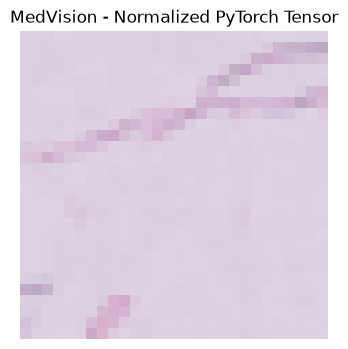

In [9]:
# Convert CHW back to HWC for Matplotlib
display_image = sample_tensor.permute(1, 2, 0).numpy()

plt.figure(figsize=(4, 4))
plt.imshow(display_image)
plt.title("MedVision - Normalized PyTorch Tensor")
plt.axis("off")
plt.show()

In [11]:
class MedVisionDataset(Dataset):

    def __init__(self, medmnist_dataset):

        self.images = medmnist_dataset.imgs
        self.labels = medmnist_dataset.labels

    def __len__(self):

        return len(self.images)

    def __getitem__(self, index):

        # Retrieve an image
        image = self.images[index]

        # Convert NumPy array to PyTorch tensor
        image = torch.from_numpy(image)

        # Change HWC to CHW
        image = image.permute(2, 0, 1)

        # Convert to float32 and normalize
        image = image.float() / 255.0

        # Convert label to a PyTorch integer tensor
        label = torch.tensor(
            int(self.labels[index][0]),
            dtype=torch.long
        )

        return image, label

In [12]:
train_data = MedVisionDataset(train_dataset)
val_data = MedVisionDataset(val_dataset)
test_data = MedVisionDataset(test_dataset)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))

Training samples: 89996
Validation samples: 10004
Testing samples: 7180


In [13]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

print("Label:", label.item())
print("Label data type:", label.dtype)

print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

Image shape: torch.Size([3, 28, 28])
Image data type: torch.float32
Label: 0
Label data type: torch.int64
Minimum pixel value: 0.6431372761726379
Maximum pixel value: 0.8941176533699036


In [14]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [15]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Batch image shape: torch.Size([64, 3, 28, 28])
Batch label shape: torch.Size([64])
Image data type: torch.float32
Label data type: torch.int64
Minimum pixel value: 0.09803921729326248
Maximum pixel value: 0.9764705896377563


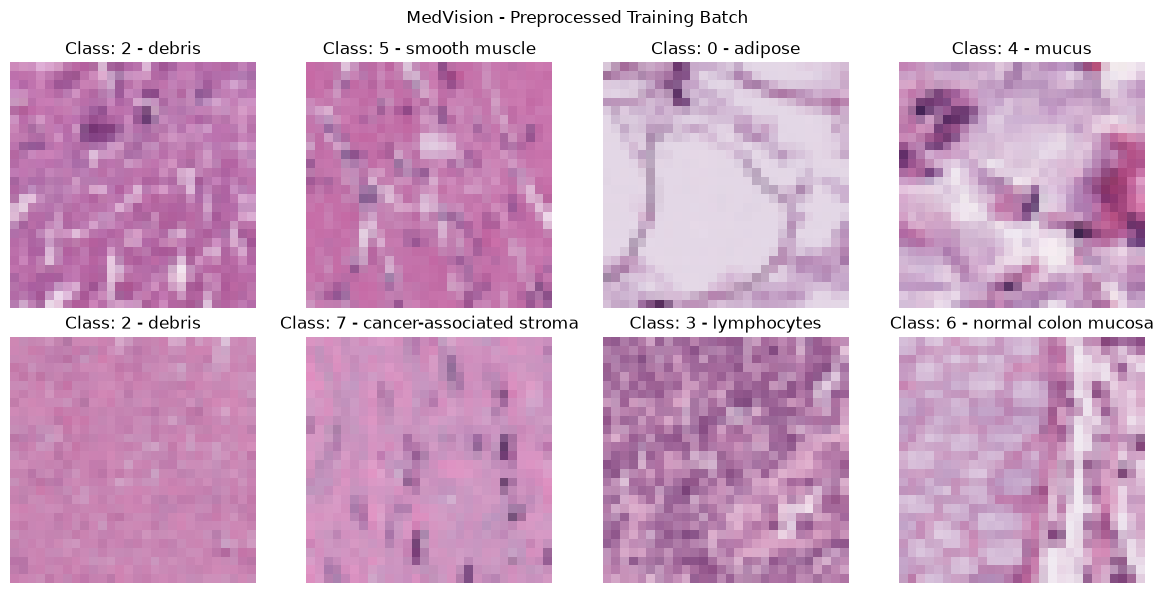

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    image = images[i].permute(1, 2, 0).numpy()
    label = labels[i].item()

    ax.imshow(image)
    ax.set_title(f"Class: {label} - {class_names[label]}")
    ax.axis("off")

plt.suptitle("MedVision - Preprocessed Training Batch")
plt.tight_layout()
plt.show()

In [21]:
print("Training samples:", len(train_data))
print("Batch size:", BATCH_SIZE)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training samples: 89996
Batch size: 64
Training batches: 1407
Validation batches: 157
Testing batches: 113
